# Do event days stand out in total sales?

**Purpose.** For each tag in the event calendar (`0_DataPreparation/events.csv`, documented in `EVENTS.md`), check whether **total daily sales** on the tagged days differ significantly from sales on the **same weekday 1, 2 and 3 weeks earlier**. This is an exploration, not a model.

**Method in plain words**
1. *Total sales* of a day = sum of `Umsatz` over all product groups.
2. **Event group:** all tagged days on which the bakery had sales.
3. **Reference group:** for every tagged day, the days exactly 7, 14 and 21 days earlier (same weekday), pooled into one group. Reference days without sales (closed) are left out, so the two groups have different sizes. For simplicity, reference days are *not* checked for tags: the last Kiel Week days are partly compared with the first Kiel Week days, which makes the Kiel Week effect look a bit smaller.
4. **Test:** Welch's t-test (two independent groups of different size and spread) on the logarithm of sales. The difference of the log means, converted back, is the *typical change in %* (event group vs. reference group). This gives **one p-value per tag**.
5. Many tags are tested at once, so chance hits become likely; we therefore also show the stricter Bonferroni threshold (0.05 ÷ number of tests).

Set `TAG` in the next cell to look at one tag in detail; the overview at the end covers all tags.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

BASE_URL = "https://raw.githubusercontent.com/opencampus-sh/intro-to-data-science-and-ml/main/data/bakery/"
TAG = "kiwo"             # tag to analyse in detail, see EVENTS.md
WEEKS_BACK = [1, 2, 3]   # reference days: exactly 1, 2 and 3 weeks earlier
ALPHA = 0.05
EVENT_COLOR, REF_COLOR = "#2a6fdb", "#9a9a9a"

sales = pd.read_csv(BASE_URL + "umsatzdaten_gekuerzt.csv", parse_dates=["Datum"])
total = sales.groupby("Datum")["Umsatz"].sum()            # total sales per day (only days with sales)
events = pd.read_csv("../0_DataPreparation/events.csv", parse_dates=["Datum"])

print(f"Sales days: {len(total)} ({total.index.min():%Y-%m-%d} – {total.index.max():%Y-%m-%d})")
print(f"Event rows: {len(events)}, tags: {events['tag'].nunique()}")

Sales days: 1819 (2013-07-01 – 2018-07-31)
Event rows: 452, tags: 17


## Event days vs. the pooled reference days

`groups_for_tag` returns the two groups as tables (date and total sales). `test_tag` compares them and returns the typical change with its 95% confidence interval and the p-value.

In [2]:
def groups_for_tag(tag, days_before=0):
    """days_before=0: the tagged days themselves; days_before=1: the day before each tagged day."""
    tag_days = sorted(events.loc[events["tag"] == tag, "Datum"])
    if days_before:
        # the day before; skipped if it carries the same tag (e.g. inside Kiel Week only the Friday before counts)
        tag_days = [d - pd.Timedelta(days=days_before) for d in tag_days
                    if d - pd.Timedelta(days=days_before) not in set(tag_days)]
    tag_days = [d for d in tag_days if total.index.min() <= d <= total.index.max()]
    event_days = [d for d in tag_days if d in total.index]
    ref_days = [d - pd.Timedelta(weeks=w) for d in event_days for w in WEEKS_BACK]
    ref_days = [d for d in ref_days if d in total.index]          # duplicates are kept on purpose
    closed = len(tag_days) - len(event_days)
    event = pd.DataFrame({"Datum": event_days, "sales": total.reindex(event_days).values})
    ref = pd.DataFrame({"Datum": ref_days, "sales": total.reindex(ref_days).values})
    return event, ref, closed


def test_tag(event, ref):
    """Welch t-test on log sales; typical change (%) of the event group vs. the reference group, with 95% CI."""
    if len(event) < 3:
        return {"n_event": len(event), "n_ref": len(ref), "change_pct": np.nan,
                "ci_low": np.nan, "ci_high": np.nan, "p_value": np.nan}
    a, b = np.log(event["sales"]), np.log(ref["sales"])
    res = stats.ttest_ind(a, b, equal_var=False)
    ci = res.confidence_interval(0.95)
    to_pct = lambda x: (np.exp(x) - 1) * 100
    return {"n_event": len(a), "n_ref": len(b), "change_pct": to_pct(a.mean() - b.mean()),
            "ci_low": to_pct(ci.low), "ci_high": to_pct(ci.high), "p_value": res.pvalue}


event, ref, closed = groups_for_tag(TAG)
result = test_tag(event, ref)
print(f"Tag '{TAG}': {result['n_event']} event days, {result['n_ref']} reference days, {closed} tagged days closed")
print(f"Typical change vs. reference days: {result['change_pct']:+.1f}% "
      f"(95% CI {result['ci_low']:+.1f}% to {result['ci_high']:+.1f}%), p = {result['p_value']:.4g}")

Tag 'kiwo': 45 event days, 135 reference days, 0 tagged days closed
Typical change vs. reference days: +16.8% (95% CI +9.6% to +24.5%), p = 6.137e-06


**What to check:** Is the event group clearly shifted against the reference group, or do the two clouds overlap a lot? Is the difference driven by a few extreme days?

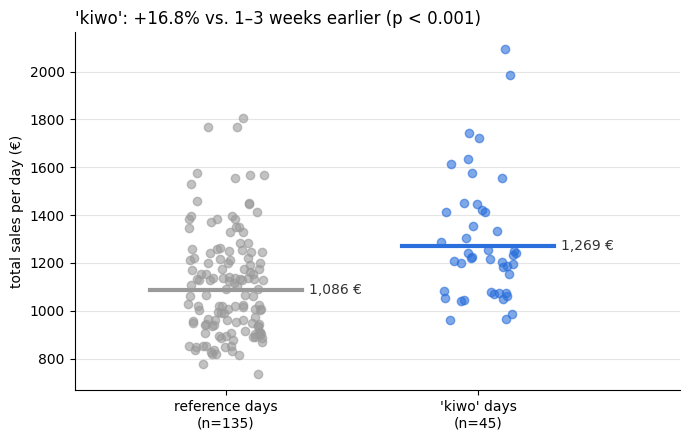

In [3]:
def p_text(p):
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"

rng = np.random.default_rng(0)   # small random sideways jitter, only so points do not hide each other
fig, ax = plt.subplots(figsize=(7, 4.5))
for x, (df, color, name) in enumerate([(ref, REF_COLOR, "reference days (1–3 weeks earlier)"),
                                       (event, EVENT_COLOR, f"'{TAG}' days")]):
    ax.plot(x + rng.uniform(-0.15, 0.15, len(df)), df["sales"], "o", color=color, alpha=0.6, markersize=6)
    geo_mean = np.exp(np.log(df["sales"]).mean())
    ax.plot([x - 0.3, x + 0.3], [geo_mean, geo_mean], color=color, linewidth=3)
    ax.text(x + 0.33, geo_mean, f"{geo_mean:,.0f} €", va="center", color="#333333")
ax.set_xticks([0, 1], [f"reference days\n(n={len(ref)})", f"'{TAG}' days\n(n={len(event)})"])
ax.set_xlim(-0.6, 1.8)
ax.set_ylabel("total sales per day (€)")
ax.set_title(f"'{TAG}': {result['change_pct']:+.1f}% vs. 1–3 weeks earlier ({p_text(result['p_value'])})", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5")
plt.tight_layout()
plt.show()

The thick line is the typical (geometric mean) sales value of each group, the value the test compares.

## Overview: all tags, and the day before

Same comparison for every tag: one test and one p-value per tag. Tags with fewer than 3 event days with sales get no test.

**The day before.** To see whether people **buy in advance** (especially before holidays on which the bakery is closed), the same test is run for the *day before* each tagged day: sales on that day vs. the same weekday 1–3 weeks earlier. If the day before carries the same tag, it is skipped (inside Kiel Week, only the Friday before the first Kiel Week day counts). The day before can carry a *different* tag (e.g. the day before Christmas Day is Christmas Eve); this is not excluded.

In [4]:
overview = []
for tag in sorted(events["tag"].unique()):
    for days_before, label in [(0, "event day"), (1, "day before")]:
        ev, rf, n_closed = groups_for_tag(tag, days_before)
        overview.append({"tag": tag, "day": label, "closed_days": n_closed, **test_tag(ev, rf)})
overview = pd.DataFrame(overview)
bonferroni = ALPHA / overview["p_value"].notna().sum()
overview["significant (p<0.05)"] = overview["p_value"] < ALPHA
overview["significant (Bonferroni)"] = overview["p_value"] < bonferroni
print(f"Bonferroni threshold: p < {bonferroni:.4f} ({overview['p_value'].notna().sum()} tests)")
overview.pivot(index="tag", columns="day",
               values=["n_event", "change_pct", "p_value", "significant (Bonferroni)"]).round(4)

Bonferroni threshold: p < 0.0019 (26 tests)


n_event            change_pct              \
day                     day before event day  day before   event day   
tag                                                                    
holiday_einheit                  5         5   11.386774   24.998097   
holiday_himmelfahrt              5         5   27.111576    47.86908   
holiday_karfreitag               4         0    74.05152         NaN   
holiday_maifeiertag              5         1   21.298895         NaN   
holiday_neujahr                  5         0  178.785307         NaN   
holiday_ostermontag              5         5   20.229571   44.639131   
holiday_pfingstmontag            5         4   10.109163   71.198261   
holiday_reformationstag          1         0         NaN         NaN   
holiday_weihnachten_1            5         0   31.774078         NaN   
holiday_weihnachten_2            0         0         NaN         NaN   
kiwo                             5        45    2.941977   16.822823   
match_holstein                  97        95   -1.936617   -2.119836   
match_thw                      127       128   -1.172671   -0.912497   
special_heiligabend              5         5   24.842264   31.774078   
special_ostersonntag             5         5   58.777916   20.229571   
special_pfingstsonntag           5         5   12.544493   10.109163   
special_silvester                5         5   51.990591  178.785307   

                           p_value           significant (Bonferroni)  \
day                     day before event day               day before   
tag                                                                     
holiday_einheit           0.137517  0.031512                    False   
holiday_himmelfahrt       0.002369  0.001429                    False   
holiday_karfreitag             0.0       NaN                     True   
holiday_maifeiertag       0.026481       NaN                    False   
holiday_neujahr                0.0       NaN                     True   
holiday_ostermontag       0.010936  0.001126                    False   
holiday_pfingstmontag     0.152149  0.000302                    False   
holiday_reformationstag        NaN       NaN                    False   
holiday_weihnachten_1     0.000037       NaN                     True   
holiday_weihnachten_2          NaN       NaN                    False   
kiwo                      0.746588  0.000006                    False   
match_holstein            0.501882  0.459824                    False   
match_thw                  0.58913  0.687667                    False   
special_heiligabend       0.000101  0.000037                     True   
special_ostersonntag           0.0  0.010936                     True   
special_pfingstsonntag    0.178122  0.152149                    False   
special_silvester              0.0       0.0                     True   

                                   
day                     event day  
tag                                
holiday_einheit             False  
holiday_himmelfahrt          True  
holiday_karfreitag          False  
holiday_maifeiertag         False  
holiday_neujahr             False  
holiday_ostermontag          True  
holiday_pfingstmontag        True  
holiday_reformationstag     False  
holiday_weihnachten_1       False  
holiday_weihnachten_2       False  
kiwo                         True  
match_holstein              False  
match_thw                   False  
special_heiligabend          True  
special_ostersonntag        False  
special_pfingstsonntag      False  
special_silvester            True

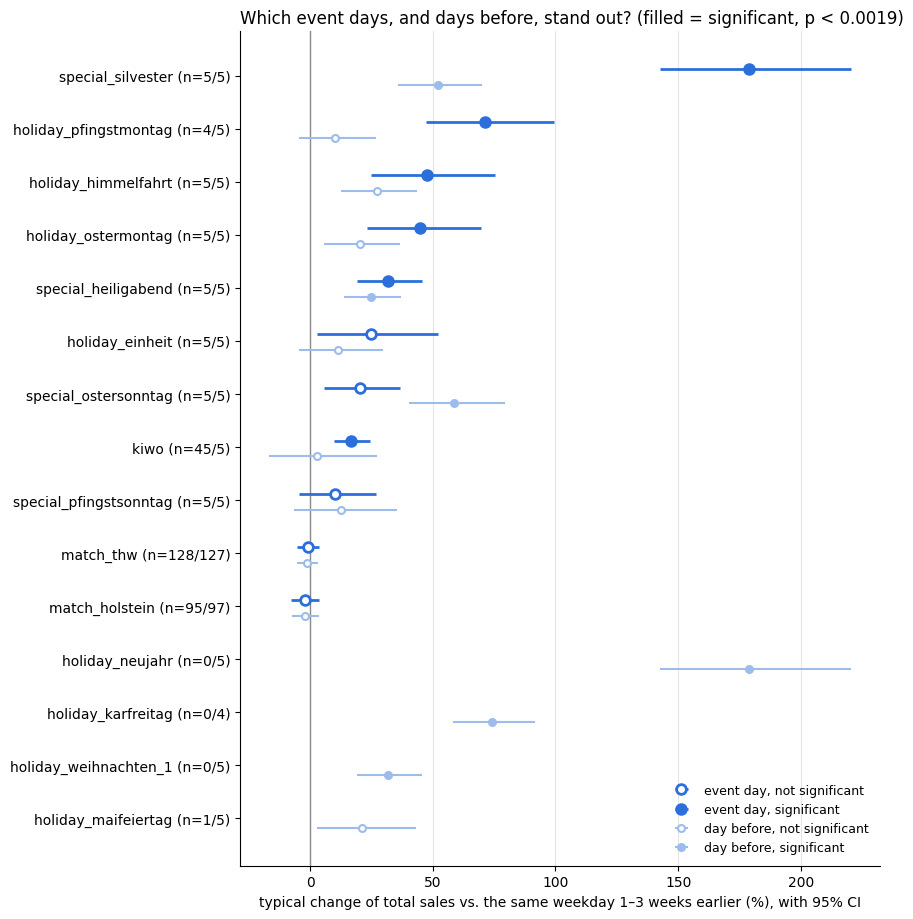

In [5]:
DAY_BEFORE_COLOR = "#9dbcec"   # same hue as the event days, less saturated
tested = overview.dropna(subset=["change_pct"])
order = (tested.pivot(index="tag", columns="day", values="change_pct")
         .reindex(columns=["event day", "day before"]).fillna(-np.inf).sort_values(["event day", "day before"]).index)
ypos = {tag: i for i, tag in enumerate(order)}
style = {"event day": dict(color=EVENT_COLOR, size=7, width=2, shift=0.12),
         "day before": dict(color=DAY_BEFORE_COLOR, size=5, width=1.5, shift=-0.18)}
fig, ax = plt.subplots(figsize=(9, 0.5 * len(order) + 1.8))
ax.axvline(0, color="#8a8a8a", linewidth=1)
for day, s in style.items():
    for significant in [False, True]:
        sub = tested[(tested["day"] == day) & ((tested["p_value"] < bonferroni) == significant)]
        ax.errorbar(sub["change_pct"], sub["tag"].map(ypos) + s["shift"],
                    xerr=[sub["change_pct"] - sub["ci_low"], sub["ci_high"] - sub["change_pct"]],
                    fmt="o", color=s["color"], ecolor=s["color"], elinewidth=s["width"], capsize=0,
                    markersize=s["size"], markeredgewidth=s["width"],
                    markerfacecolor=s["color"] if significant else "white",
                    label=f"{day}, " + ("significant" if significant else "not significant"))
n = overview.pivot(index="tag", columns="day", values="n_event")
ax.set_yticks(range(len(order)), [f"{t} (n={int(n.loc[t, 'event day'])}/{int(n.loc[t, 'day before'])})" for t in order])
ax.set_xlabel("typical change of total sales vs. the same weekday 1–3 weeks earlier (%), with 95% CI")
ax.set_title(f"Which event days, and days before, stand out? (filled = significant, p < {bonferroni:.4f})", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#e5e5e5")
ax.legend(frameon=False, loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

**What to check:** For holidays on which the bakery is closed (only a light "day before" point, no dark point), is the day before clearly higher? That would point to buying in advance. Which tags clear the strict threshold, and is the direction plausible? Tags with few event days (n ≈ 5) have wide intervals: a large but non-significant change may still matter. Tags on which the bakery is closed (see `closed_days`) are better handled as "closed" than as a sales effect.

**Limits**
- The groups are compared as independent groups. The link between an event day and *its own* reference days is not used, so differences between years (e.g. a strong 2014 and a weak 2016) add noise.
- Reference days are not checked for tags: they can themselves be event days (other Kiel Week days, or a holiday 1–3 weeks before another holiday).
- Total sales are lower on days where a product group has no row (e.g. group 4 missing on 53 days, group 6 only in season), which adds noise.